In [ ]:
!unzip -q /content/*.zip -d /content/wood_new

In [ ]:
from pathlib import Path
from collections import Counter

ROOT = Path("/content/wood_new")
exts = {".png", ".jpg", ".jpeg", ".bmp"}

print("images:", sum(1 for f in ROOT.rglob("*") if f.suffix.lower() in exts))
print("label .txt files:", sum(1 for f in ROOT.rglob("*.txt")))
for p in sorted(ROOT.rglob("*")):
    if p.is_dir():
        n = sum(1 for f in p.iterdir() if f.suffix.lower() in exts)
        if n:
            print(n, "images ->", p.relative_to(ROOT))

yaml = list(ROOT.rglob("*.yaml"))
print(yaml)
if yaml:
    print(yaml[0].read_text())

classes = Counter()
empty = 0
for f in ROOT.rglob("*.txt"):
    lines = f.read_text().strip().splitlines()
    if not lines:
        empty += 1
    for line in lines:
        classes[line.split()[0]] += 1
print("class ids in labels:", dict(classes))
print("empty label files:", empty)

images: 4000
label .txt files: 0
4000 images -> Images - 1
[]
class ids in labels: {}
empty label files: 0


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

!cp "/content/drive/MyDrive/DL/course/Images - 1.zip" /content/images.zip
!unzip -q /content/images.zip -d /content/images_raw

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
replace /content/images_raw/Images - 1/100000000.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

In [ ]:
from pathlib import Path
from collections import Counter

exts = {".png", ".jpg", ".jpeg", ".bmp"}
imgs = {f.stem: f for f in Path("/content/images_raw").rglob("*") if f.suffix.lower() in exts}
labs = {f.stem: f for f in Path("/content/wood_new").rglob("*.txt")}
print("images:", len(imgs), "| labels:", len(labs), "| matched:", len(set(imgs) & set(labs)))

classes = Counter()
empty = only0 = 0
for f in labs.values():
    ids = [l.split()[0] for l in f.read_text().strip().splitlines()]
    if not ids:
        empty += 1
    elif set(ids) == {"0"}:
        only0 += 1
    classes.update(ids)
print(sorted(classes.items()))
print("empty label files:", empty, "| files with only class 0:", only0)

images: 4000 | labels: 4000 | matched: 4000
[('0', 171), ('1', 4070), ('2', 206), ('3', 650), ('4', 2934), ('5', 542), ('6', 121), ('7', 517)]
empty label files: 388 | files with only class 0: 19


In [ ]:
NO_DEFECT_IDS = set()
NO_DEFECT_IDS = set()        # only empty label files count as good      # only empty label files count as good

In [ ]:
import numpy as np, pandas as pd, tensorflow as tf
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, roc_curve
from tensorflow import keras
from tensorflow.keras import layers
from google.colab import drive

drive.mount("/content/drive")
print("GPU:", tf.config.list_physical_devices("GPU"))

IMG_DIR = Path("/content/images_raw")
LAB_DIR = Path("/content/wood_new")
SAVE_DIR = Path("/content/drive/MyDrive/DL/course")
NO_DEFECT_IDS = {"0"}        # class ids that mean "no defect"
IMG_SIZE, BATCH, SEED = 224, 32, 42
AUTOTUNE = tf.data.AUTOTUNE

# ---- file list: empty label file or only no-defect boxes = good (0), else defect (1) ----
exts = {".png", ".jpg", ".jpeg", ".bmp"}
imgs = {f.stem: f for f in IMG_DIR.rglob("*") if f.suffix.lower() in exts}
rows = []
for lf in LAB_DIR.rglob("*.txt"):
    if lf.stem not in imgs:
        continue
    ids = [l.split()[0] for l in lf.read_text().strip().splitlines()]
    defect = any(i not in NO_DEFECT_IDS for i in ids)
    rows.append({"path": str(imgs[lf.stem]), "label": int(defect),
                 "classes": ",".join(sorted(set(ids)))})
df = pd.DataFrame(rows)
print("matched:", len(df), df["label"].value_counts().to_dict())

trainval_df, test_df = train_test_split(df, test_size=0.15, stratify=df["label"], random_state=SEED)
train_df, val_df = train_test_split(trainval_df, test_size=0.15 / 0.85,
                                    stratify=trainval_df["label"], random_state=SEED)
for n, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(n, len(d), d["label"].value_counts().to_dict())

def load(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    img = tf.cast(tf.round(img), tf.uint8)
    return img, tf.reshape(label, [1])

def make_ds(d, training):
    ds = tf.data.Dataset.from_tensor_slices((d["path"].values, d["label"].values.astype("float32")))
    ds = ds.map(load, num_parallel_calls=AUTOTUNE).cache()
    if training:
        ds = ds.shuffle(len(d), seed=SEED)
    ds = ds.batch(BATCH).map(lambda x, y: (tf.cast(x, tf.float32), y), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

train_ds, val_ds, test_ds = make_ds(train_df, True), make_ds(val_df, False), make_ds(test_df, False)

n0, n1 = (train_df["label"] == 0).sum(), (train_df["label"] == 1).sum()
class_weight = {0: len(train_df) / (2.0 * n0), 1: len(train_df) / (2.0 * n1)}
print("class_weight:", class_weight)

# ---- model ----
augment = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.1),
    layers.RandomBrightness(0.1),
    layers.RandomContrast(0.1),
])
base = keras.applications.EfficientNetB0(include_top=False, weights="imagenet",
                                         input_shape=(IMG_SIZE, IMG_SIZE, 3))
base.trainable = False
inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = augment(inputs)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)
model = keras.Model(inputs, outputs)

def compile_model(lr):
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy",
                  metrics=["accuracy",
                           keras.metrics.Precision(name="precision"),
                           keras.metrics.Recall(name="recall"),
                           keras.metrics.AUC(name="auc")])

def callbacks():
    return [keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2)]

compile_model(1e-3)
model.fit(train_ds, validation_data=val_ds, epochs=15, class_weight=class_weight,
          callbacks=callbacks(), verbose=2)

base.trainable = True
for l in base.layers[:-30]:
    l.trainable = False
for l in base.layers:
    if isinstance(l, layers.BatchNormalization):
        l.trainable = False
compile_model(1e-4)
model.fit(train_ds, validation_data=val_ds, epochs=15, class_weight=class_weight,
          callbacks=callbacks(), verbose=2)

# ---- threshold from validation only, then ONE test evaluation ----
y_val = val_df["label"].values
p_val = model.predict(val_ds, verbose=0).ravel()
fpr, tpr, thr = roc_curve(y_val, p_val)
threshold = float(thr[np.argmax(tpr - fpr)])
print("threshold (from validation):", threshold)

SAVE_DIR.mkdir(parents=True, exist_ok=True)
model.save(SAVE_DIR / "wood_model_new.keras")
(SAVE_DIR / "wood_model_new_threshold.txt").write_text(str(threshold))
test_df.to_csv(SAVE_DIR / "wood_test_split.csv", index=False)

y_test = test_df["label"].values
p_test = model.predict(test_ds, verbose=0).ravel()
print("test AUC:", round(roc_auc_score(y_test, p_test), 4))
for name, t in [("0.5", 0.5), ("validation threshold", threshold)]:
    print(f"\n--- test at threshold {name} ---")
    print(confusion_matrix(y_test, p_test > t))
    print(classification_report(y_test, p_test > t, target_names=["good", "defect"]))

print("recall per defect class id (test):")
pred = p_test > threshold
for c in sorted({i for s in test_df["classes"] for i in s.split(",") if i} - NO_DEFECT_IDS):
    m = test_df["classes"].apply(lambda s: c in s.split(",")).values
    print(f"  class {c}: {pred[m].mean():.2f}  ({m.sum()} images)")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
matched: 4000 {1: 3593, 0: 407}
train 2800 {1: 2515, 0: 285}
val 600 {1: 539, 0: 61}
test 600 {1: 539, 0: 61}
class_weight: {0: np.float64(4.912280701754386), 1: np.float64(0.5566600397614314)}
Epoch 1/15
88/88 - 72s - 819ms/step - accuracy: 0.7282 - auc: 0.8584 - loss: 0.5036 - precision: 0.9777 - recall: 0.7137 - val_accuracy: 0.8567 - val_auc: 0.9330 - val_loss: 0.3405 - val_precision: 0.9871 - val_recall: 0.8516 - learning_rate: 0.0010
Epoch 2/15
88/88 - 8s - 93ms/step - accuracy: 0.8214 - auc: 0.9240 - loss: 0.3763 - precision: 0.9860 - recall: 0.8127 - val_accuracy: 0.8900 - val_auc: 0.9385 - val_loss: 0.2512 - val_precision: 0.9739 - val_recall: 0.9017 - learning_rate: 0.0010
Epoch 3/15
88/88 - 8s - 95ms/step - accuracy: 0.8236 - auc: 0.9176 - loss: 0.3690 - precision: 0.9847 - rec

In [ ]:
base.trainable = True
for l in base.layers[:-100]:
    l.trainable = False
for l in base.layers:
    if isinstance(l, layers.BatchNormalization):
        l.trainable = False

compile_model(1e-5)
model.fit(train_ds, validation_data=val_ds, epochs=20,
          class_weight=class_weight, callbacks=callbacks(), verbose=2)

y_val = val_df["label"].values
p_val = model.predict(val_ds, verbose=0).ravel()
fpr, tpr, thr = roc_curve(y_val, p_val)
threshold = float(thr[np.argmax(tpr - fpr)])
print("val AUC:", round(roc_auc_score(y_val, p_val), 4), "| threshold:", threshold)

model.save(SAVE_DIR / "wood_model_new_ft2.keras")
(SAVE_DIR / "wood_model_new_ft2_threshold.txt").write_text(str(threshold))

p_test = model.predict(test_ds, verbose=0).ravel()
print("test AUC:", round(roc_auc_score(y_test, p_test), 4))
print(confusion_matrix(y_test, p_test > threshold))
print(classification_report(y_test, p_test > threshold, target_names=["good", "defect"]))

Epoch 1/20
88/88 - 32s - 362ms/step - accuracy: 0.9014 - auc: 0.9677 - loss: 0.2148 - precision: 0.9925 - recall: 0.8970 - val_accuracy: 0.8767 - val_auc: 0.9665 - val_loss: 0.2968 - val_precision: 0.9915 - val_recall: 0.8701 - learning_rate: 1.0000e-05
Epoch 2/20
88/88 - 9s - 99ms/step - accuracy: 0.8893 - auc: 0.9685 - loss: 0.2103 - precision: 0.9942 - recall: 0.8819 - val_accuracy: 0.8817 - val_auc: 0.9666 - val_loss: 0.2707 - val_precision: 0.9916 - val_recall: 0.8757 - learning_rate: 1.0000e-05
Epoch 3/20
88/88 - 9s - 98ms/step - accuracy: 0.8968 - auc: 0.9675 - loss: 0.2149 - precision: 0.9934 - recall: 0.8911 - val_accuracy: 0.8783 - val_auc: 0.9668 - val_loss: 0.2844 - val_precision: 0.9916 - val_recall: 0.8720 - learning_rate: 1.0000e-05
Epoch 4/20
88/88 - 9s - 99ms/step - accuracy: 0.8850 - auc: 0.9705 - loss: 0.2107 - precision: 0.9928 - recall: 0.8783 - val_accuracy: 0.8817 - val_auc: 0.9667 - val_loss: 0.2738 - val_precision: 0.9916 - val_recall: 0.8757 - learning_rate: 1

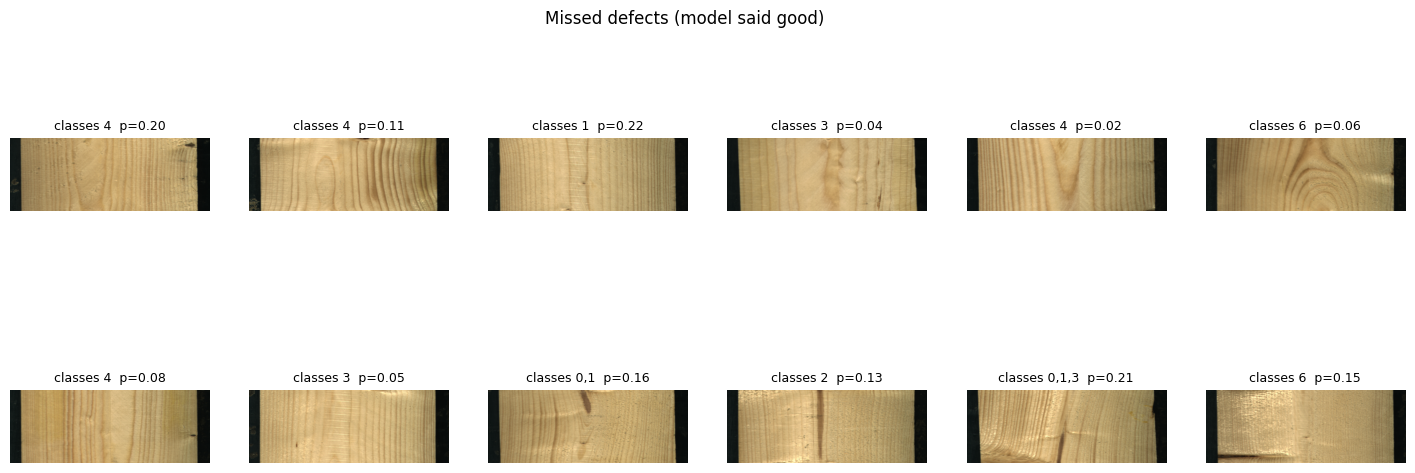

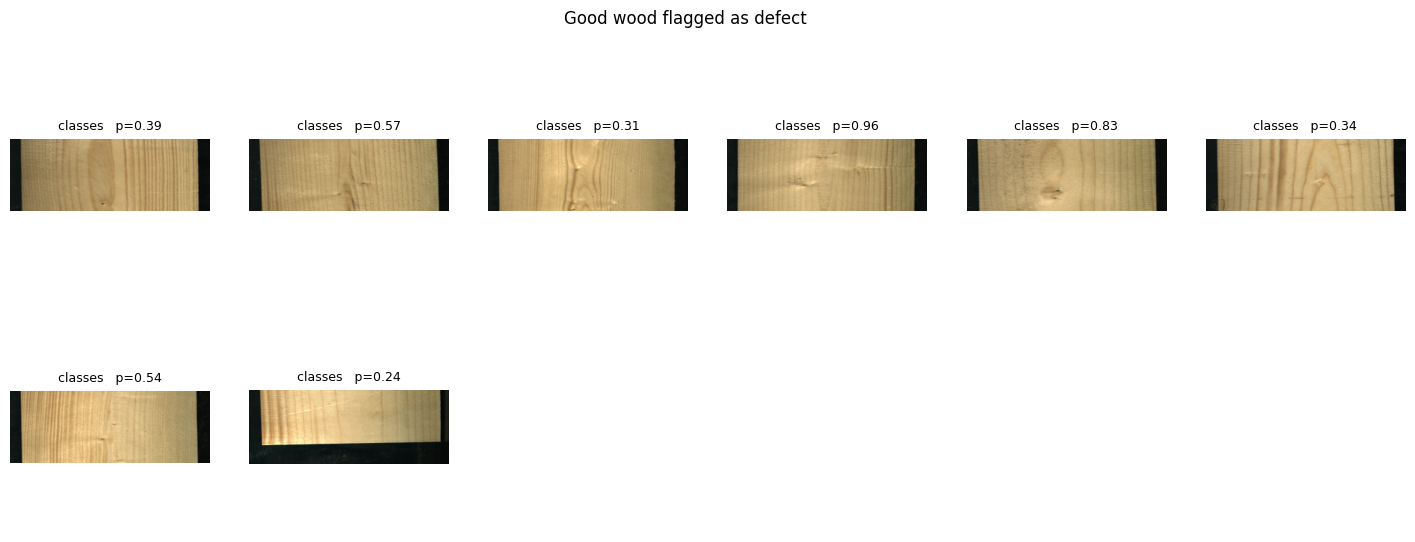

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

pred = p_test > threshold
t = test_df.reset_index(drop=True)
missed = t.index[(t["label"] == 1) & (~pred)].tolist()[:12]
false_alarm = t.index[(t["label"] == 0) & pred].tolist()[:8]

def show(idx, title):
    fig, axes = plt.subplots(2, 6, figsize=(18, 6))
    for ax in axes.ravel():
        ax.axis("off")
    for ax, i in zip(axes.ravel(), idx):
        ax.imshow(Image.open(t.loc[i, "path"]))
        ax.set_title(f"classes {t.loc[i, 'classes']}  p={p_test[i]:.2f}", fontsize=9)
    fig.suptitle(title)
    plt.show()

show(missed, "Missed defects (model said good)")
show(false_alarm, "Good wood flagged as defect")

In [ ]:
from PIL import Image

w0, h0 = Image.open(train_df["path"].iloc[0]).size
IMG_W = 512
IMG_H = max(32, int(round(IMG_W * h0 / w0 / 32)) * 32)
print("original size:", (w0, h0), "-> training size:", (IMG_W, IMG_H))

def load2(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG_H, IMG_W))
    return tf.cast(tf.round(img), tf.uint8), tf.reshape(label, [1])

def make_ds2(d, training):
    ds = tf.data.Dataset.from_tensor_slices((d["path"].values, d["label"].values.astype("float32")))
    ds = ds.map(load2, num_parallel_calls=AUTOTUNE).cache()
    if training:
        ds = ds.shuffle(len(d), seed=SEED)
    ds = ds.batch(BATCH).map(lambda x, y: (tf.cast(x, tf.float32), y), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

train_ds2, val_ds2, test_ds2 = make_ds2(train_df, True), make_ds2(val_df, False), make_ds2(test_df, False)

keras.backend.clear_session()
augment2 = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomBrightness(0.1),
    layers.RandomContrast(0.1),
])
base = keras.applications.EfficientNetB0(include_top=False, weights="imagenet",
                                         input_shape=(IMG_H, IMG_W, 3))
base.trainable = False
inputs = keras.Input(shape=(IMG_H, IMG_W, 3))
x = augment2(inputs)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)
model = keras.Model(inputs, outputs)

compile_model(1e-3)
model.fit(train_ds2, validation_data=val_ds2, epochs=15, class_weight=class_weight,
          callbacks=callbacks(), verbose=2)

base.trainable = True
for l in base.layers[:-30]:
    l.trainable = False
for l in base.layers:
    if isinstance(l, layers.BatchNormalization):
        l.trainable = False
compile_model(1e-4)
model.fit(train_ds2, validation_data=val_ds2, epochs=15, class_weight=class_weight,
          callbacks=callbacks(), verbose=2)

original size: (2800, 1024) -> training size: (512, 192)
Epoch 1/15
88/88 - 121s - 1s/step - accuracy: 0.7079 - auc: 0.8418 - loss: 0.5034 - precision: 0.9701 - recall: 0.6962 - val_accuracy: 0.8133 - val_auc: 0.9443 - val_loss: 0.4106 - val_precision: 0.9954 - val_recall: 0.7959 - learning_rate: 0.0010
Epoch 2/15
88/88 - 7s - 79ms/step - accuracy: 0.8100 - auc: 0.9143 - loss: 0.3865 - precision: 0.9839 - recall: 0.8016 - val_accuracy: 0.8100 - val_auc: 0.9532 - val_loss: 0.3729 - val_precision: 0.9930 - val_recall: 0.7941 - learning_rate: 0.0010
Epoch 3/15
88/88 - 7s - 85ms/step - accuracy: 0.8257 - auc: 0.9357 - loss: 0.3350 - precision: 0.9870 - recall: 0.8167 - val_accuracy: 0.8550 - val_auc: 0.9556 - val_loss: 0.3117 - val_precision: 0.9871 - val_recall: 0.8497 - learning_rate: 0.0010
Epoch 4/15
88/88 - 7s - 78ms/step - accuracy: 0.8486 - auc: 0.9422 - loss: 0.3154 - precision: 0.9879 - recall: 0.8417 - val_accuracy: 0.8000 - val_auc: 0.9573 - val_loss: 0.3871 - val_precision: 0.9

In [ ]:
compile_model(5e-5)
model.fit(train_ds2, validation_data=val_ds2, epochs=30, class_weight=class_weight,
          callbacks=callbacks(), verbose=2)

p_val = model.predict(val_ds2, verbose=0).ravel()
fpr, tpr, thr = roc_curve(y_val, p_val)
threshold = float(thr[np.argmax(tpr - fpr)])
print("val AUC:", round(roc_auc_score(y_val, p_val), 4), "| threshold:", threshold)

model.save(SAVE_DIR / "wood_model_wide2.keras")
(SAVE_DIR / "wood_model_wide2_threshold.txt").write_text(str(threshold))

p_test = model.predict(test_ds2, verbose=0).ravel()
print("test AUC:", round(roc_auc_score(y_test, p_test), 4))
print(confusion_matrix(y_test, p_test > threshold))
print(classification_report(y_test, p_test > threshold, target_names=["good", "defect"]))

Epoch 1/30
88/88 - 62s - 705ms/step - accuracy: 0.9361 - auc: 0.9879 - loss: 0.1285 - precision: 0.9970 - recall: 0.9316 - val_accuracy: 0.9500 - val_auc: 0.9880 - val_loss: 0.1120 - val_precision: 0.9942 - val_recall: 0.9499 - learning_rate: 5.0000e-05
Epoch 2/30
88/88 - 8s - 86ms/step - accuracy: 0.9457 - auc: 0.9912 - loss: 0.1080 - precision: 0.9983 - recall: 0.9412 - val_accuracy: 0.9283 - val_auc: 0.9866 - val_loss: 0.1523 - val_precision: 0.9960 - val_recall: 0.9239 - learning_rate: 5.0000e-05
Epoch 3/30
88/88 - 8s - 86ms/step - accuracy: 0.9418 - auc: 0.9888 - loss: 0.1176 - precision: 0.9979 - recall: 0.9372 - val_accuracy: 0.9283 - val_auc: 0.9865 - val_loss: 0.1660 - val_precision: 0.9980 - val_recall: 0.9221 - learning_rate: 5.0000e-05
Epoch 4/30
88/88 - 8s - 86ms/step - accuracy: 0.9525 - auc: 0.9910 - loss: 0.1011 - precision: 0.9979 - recall: 0.9491 - val_accuracy: 0.9350 - val_auc: 0.9867 - val_loss: 0.1474 - val_precision: 0.9960 - val_recall: 0.9314 - learning_rate: 2

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

!ls -lh "/content/drive/MyDrive/DL/course/"
!cp "/content/drive/MyDrive/DL/course/Images - 1.zip" /content/images.zip
!unzip -q /content/images.zip -d /content/images_raw
!ls /content/images_raw | head -3

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
total 3.2G
-rw------- 1 root root 3.1G Oct 24 15:26 'Images - 1.zip'
-rw------- 1 root root  28M Oct 24 16:11  wood_model_new_ft2.keras
-rw------- 1 root root   19 Oct 24 16:11  wood_model_new_ft2_threshold.txt
-rw------- 1 root root  28M Oct 24 16:05  wood_model_new.keras
-rw------- 1 root root   18 Oct 24 16:05  wood_model_new_threshold.txt
-rw------- 1 root root  28M Oct 24 16:26  wood_model_wide2.keras
-rw------- 1 root root   18 Oct 24 16:26  wood_model_wide2_threshold.txt
-rw------- 1 root root  30K Oct 24 16:05  wood_test_split.csv
Images - 1


In [ ]:
!ls /content/*.zip
!unzip -q "/content/Bounding Boxes - YOLO Format - 1.zip" -d /content/wood_new
!ls /content/wood_new | head -3

/content/images.zip
unzip:  cannot find or open /content/Bounding Boxes - YOLO Format - 1.zip, /content/Bounding Boxes - YOLO Format - 1.zip.zip or /content/Bounding Boxes - YOLO Format - 1.zip.ZIP.
ls: cannot access '/content/wood_new': No such file or directory


In [ ]:
!cp "/content/drive/MyDrive/DL/course/Bounding Boxes - YOLO Format - 1.zip" /content/labels.zip
!unzip -q /content/labels.zip -d /content/wood_new
!ls /content/wood_new | head -3

cp: cannot stat '/content/drive/MyDrive/DL/course/Bounding Boxes - YOLO Format - 1.zip': No such file or directory
unzip:  cannot find or open /content/labels.zip, /content/labels.zip.zip or /content/labels.zip.ZIP.
ls: cannot access '/content/wood_new': No such file or directory


In [ ]:
import numpy as np, pandas as pd, tensorflow as tf
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from tensorflow import keras
from google.colab import drive

drive.mount("/content/drive")
SAVE_DIR = Path("/content/drive/MyDrive/DL/course")
IMG_DIR, LAB_DIR = Path("/content/images_raw"), Path("/content/wood_new")
print("files on Drive:", sorted(p.name for p in SAVE_DIR.glob("wood_*")))
assert IMG_DIR.exists() and LAB_DIR.exists(), "images/labels are gone: run the unzip cells again first"

SEED, BATCH = 42, 32
AUTOTUNE = tf.data.AUTOTUNE
NO_DEFECT_IDS = {"0"}          # same as in the training run

exts = {".png", ".jpg", ".jpeg", ".bmp"}
imgs = {f.stem: f for f in IMG_DIR.rglob("*") if f.suffix.lower() in exts}
rows = []
for lf in LAB_DIR.rglob("*.txt"):
    if lf.stem not in imgs:
        continue
    ids = [l.split()[0] for l in lf.read_text().strip().splitlines()]
    defect = any(i not in NO_DEFECT_IDS for i in ids)
    rows.append({"path": str(imgs[lf.stem]), "label": int(defect), "classes": ",".join(sorted(set(ids)))})
df = pd.DataFrame(rows)

trainval_df, test_df = train_test_split(df, test_size=0.15, stratify=df["label"], random_state=SEED)
train_df, val_df = train_test_split(trainval_df, test_size=0.15 / 0.85,
                                    stratify=trainval_df["label"], random_state=SEED)
saved = pd.read_csv(SAVE_DIR / "wood_test_split.csv")
print("test split matches saved:", set(saved["path"]) == set(test_df["path"]))

name = "wood_model_wide2.keras" if (SAVE_DIR / "wood_model_wide2.keras").exists() else "wood_model_wide.keras"
model = keras.models.load_model(SAVE_DIR / name)
IMG_H, IMG_W = model.input_shape[1:3]
print("model:", name, "| input size:", (IMG_H, IMG_W))

def load2(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG_H, IMG_W))
    return img, tf.reshape(label, [1])

def make_ds2(d):
    ds = tf.data.Dataset.from_tensor_slices((d["path"].values, d["label"].values.astype("float32")))
    return ds.map(load2, num_parallel_calls=AUTOTUNE).batch(BATCH).prefetch(AUTOTUNE)

y_val, y_test = val_df["label"].values, test_df["label"].values
p_val = model.predict(make_ds2(val_df), verbose=0).ravel()
p_test = model.predict(make_ds2(test_df), verbose=0).ravel()
print("val AUC:", round(roc_auc_score(y_val, p_val), 4), "| test AUC:", round(roc_auc_score(y_test, p_test), 4))

print("\nthr  | val missed/false alarms | test missed/false alarms")
for t in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    pv, pt = p_val > t, p_test > t
    vfn = int(((~pv) & (y_val == 1)).sum()); vfp = int((pv & (y_val == 0)).sum())
    tfn = int(((~pt) & (y_test == 1)).sum()); tfp = int((pt & (y_test == 0)).sum())
    print(f"{t:.1f}  | {vfn:3d} / {vfp:2d}                | {tfn:3d} / {tfp:2d}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
files on Drive: ['wood_model_new.keras', 'wood_model_new_ft2.keras', 'wood_model_new_ft2_threshold.txt', 'wood_model_new_threshold.txt', 'wood_model_wide2.keras', 'wood_model_wide2_threshold.txt', 'wood_test_split.csv']


AssertionError: images/labels are gone: run the unzip cells again first

In [ ]:
from google.colab import files
uploaded = files.upload()
print(list(uploaded.keys()))

Saving Bounding Boxes - YOLO Format - 1.zip to Bounding Boxes - YOLO Format - 1.zip
['Bounding Boxes - YOLO Format - 1.zip']


In [ ]:
import glob, zipfile
for z in glob.glob("/content/*.zip"):
    if z.endswith("images.zip"):
        continue
    print("unzipping", z)
    zipfile.ZipFile(z).extractall("/content/wood_new")

!ls /content/wood_new | head -3

unzipping /content/Bounding Boxes - YOLO Format - 1.zip
Bounding Boxes - YOLO Format - 1
Images - 1


In [ ]:
import numpy as np, pandas as pd, tensorflow as tf
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from tensorflow import keras
from google.colab import drive

drive.mount("/content/drive")
SAVE_DIR = Path("/content/drive/MyDrive/DL/course")
IMG_DIR, LAB_DIR = Path("/content/images_raw"), Path("/content/wood_new")
print("files on Drive:", sorted(p.name for p in SAVE_DIR.glob("wood_*")))
assert IMG_DIR.exists() and LAB_DIR.exists(), "images/labels are gone: run the unzip cells again first"

SEED, BATCH = 42, 32
AUTOTUNE = tf.data.AUTOTUNE
NO_DEFECT_IDS = {"0"}          # same as in the training run

exts = {".png", ".jpg", ".jpeg", ".bmp"}
imgs = {f.stem: f for f in IMG_DIR.rglob("*") if f.suffix.lower() in exts}
rows = []
for lf in LAB_DIR.rglob("*.txt"):
    if lf.stem not in imgs:
        continue
    ids = [l.split()[0] for l in lf.read_text().strip().splitlines()]
    defect = any(i not in NO_DEFECT_IDS for i in ids)
    rows.append({"path": str(imgs[lf.stem]), "label": int(defect), "classes": ",".join(sorted(set(ids)))})
df = pd.DataFrame(rows)

trainval_df, test_df = train_test_split(df, test_size=0.15, stratify=df["label"], random_state=SEED)
train_df, val_df = train_test_split(trainval_df, test_size=0.15 / 0.85,
                                    stratify=trainval_df["label"], random_state=SEED)
saved = pd.read_csv(SAVE_DIR / "wood_test_split.csv")
print("test split matches saved:", set(saved["path"]) == set(test_df["path"]))

name = "wood_model_wide2.keras" if (SAVE_DIR / "wood_model_wide2.keras").exists() else "wood_model_wide.keras"
model = keras.models.load_model(SAVE_DIR / name)
IMG_H, IMG_W = model.input_shape[1:3]
print("model:", name, "| input size:", (IMG_H, IMG_W))

def load2(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG_H, IMG_W))
    return img, tf.reshape(label, [1])

def make_ds2(d):
    ds = tf.data.Dataset.from_tensor_slices((d["path"].values, d["label"].values.astype("float32")))
    return ds.map(load2, num_parallel_calls=AUTOTUNE).batch(BATCH).prefetch(AUTOTUNE)

y_val, y_test = val_df["label"].values, test_df["label"].values
p_val = model.predict(make_ds2(val_df), verbose=0).ravel()
p_test = model.predict(make_ds2(test_df), verbose=0).ravel()
print("val AUC:", round(roc_auc_score(y_val, p_val), 4), "| test AUC:", round(roc_auc_score(y_test, p_test), 4))

print("\nthr  | val missed/false alarms | test missed/false alarms")
for t in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    pv, pt = p_val > t, p_test > t
    vfn = int(((~pv) & (y_val == 1)).sum()); vfp = int((pv & (y_val == 0)).sum())
    tfn = int(((~pt) & (y_test == 1)).sum()); tfp = int((pt & (y_test == 0)).sum())
    print(f"{t:.1f}  | {vfn:3d} / {vfp:2d}                | {tfn:3d} / {tfp:2d}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
files on Drive: ['wood_model_new.keras', 'wood_model_new_ft2.keras', 'wood_model_new_ft2_threshold.txt', 'wood_model_new_threshold.txt', 'wood_model_wide2.keras', 'wood_model_wide2_threshold.txt', 'wood_test_split.csv']
test split matches saved: True
model: wood_model_wide2.keras | input size: (192, 512)
val AUC: 0.9881 | test AUC: 0.9848

thr  | val missed/false alarms | test missed/false alarms
0.2  |  10 / 11                |  14 / 11
0.3  |  15 /  8                |  20 /  7
0.4  |  22 /  4                |  26 /  3
0.5  |  27 /  3                |  32 /  3
0.6  |  31 /  3                |  38 /  3
0.7  |  37 /  1                |  41 /  2
0.8  |  48 /  1                |  44 /  2


In [ ]:
THRESHOLD = 0.3
(SAVE_DIR / "wood_model_wide2_threshold.txt").write_text(str(THRESHOLD))

def predict(path):
    img = tf.io.read_file(str(path))
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG_H, IMG_W))
    p = float(model.predict(img[None], verbose=0)[0][0])
    return ("defect" if p > THRESHOLD else "good"), round(p, 3)

for f in sorted(Path("/content/images_raw").rglob("*.jpg"))[:5]:
    print(f.name, predict(f))

100000000.jpg ('defect', 0.588)
100000001.jpg ('good', 0.066)
100000002.jpg ('defect', 0.996)
100000003.jpg ('defect', 0.852)
100000004.jpg ('defect', 0.836)


In [ ]:
from google.colab import files
uploaded = files.upload()
print(list(uploaded.keys()))

Saving wood_model_final.keras to wood_model_final.keras
['wood_model_final.keras']


In [ ]:
from tensorflow.keras import layers
from sklearn.metrics import confusion_matrix, classification_report

S = 224
oldaug = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.1),
    layers.RandomBrightness(0.1),
    layers.RandomContrast(0.1),
])
old_base = keras.applications.EfficientNetB0(include_top=False, weights=None, input_shape=(S, S, 3))
inp = keras.Input(shape=(S, S, 3))
x = oldaug(inp)
x = layers.Lambda(lambda t: tf.cast(t, tf.float32), output_shape=(S, S, 3))(x)
x = old_base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
out = layers.Dense(1, activation="sigmoid")(x)
old_model = keras.Model(inp, out)
old_model.load_weights("/content/wood_model_final.keras")

def load_old(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, (S, S))
    return img, tf.reshape(label, [1])

ds_old = tf.data.Dataset.from_tensor_slices(
    (test_df["path"].values, test_df["label"].values.astype("float32")))
ds_old = ds_old.map(load_old).batch(32).prefetch(tf.data.AUTOTUNE)

p_old = old_model.predict(ds_old, verbose=0).ravel()
print("old MVTec model on the new test set, AUC:", round(roc_auc_score(y_test, p_old), 4))
for t in (0.5, 0.2, 0.8):
    print(f"\n--- threshold {t} ---")
    print(confusion_matrix(y_test, p_old > t))
    print(classification_report(y_test, p_old > t, target_names=["good", "defect"]))

old MVTec model on the new test set, AUC: 0.8855

--- threshold 0.5 ---
[[  9  52]
 [  2 537]]
              precision    recall  f1-score   support

        good       0.82      0.15      0.25        61
      defect       0.91      1.00      0.95       539

    accuracy                           0.91       600
   macro avg       0.86      0.57      0.60       600
weighted avg       0.90      0.91      0.88       600


--- threshold 0.2 ---
[[  3  58]
 [  0 539]]
              precision    recall  f1-score   support

        good       1.00      0.05      0.09        61
      defect       0.90      1.00      0.95       539

    accuracy                           0.90       600
   macro avg       0.95      0.52      0.52       600
weighted avg       0.91      0.90      0.86       600


--- threshold 0.8 ---
[[ 18  43]
 [  7 532]]
              precision    recall  f1-score   support

        good       0.72      0.30      0.42        61
      defect       0.93      0.99      0.96       

In [1]:
import os
from google.colab import userdata

!pip install -q -U kaggle
os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

!kaggle datasets list -s "wood defect" | head -8

Authentication required to call the Kaggle API.

First, you will need a Kaggle account. You can sign up at
  https://www.kaggle.com/account/login

Recommended: log in with OAuth via a web-based authorization flow.
No token to manage; credentials are cached locally for you.
    kaggle auth login


In [2]:
import os
from google.colab import userdata

token = userdata.get("KAGGLE_API_TOKEN").strip()
os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
path = os.path.expanduser("~/.kaggle/access_token")
with open(path, "w") as f:
    f.write(token)
os.chmod(path, 0o600)
os.environ["KAGGLE_API_TOKEN"] = token

print("token length:", len(token), "| starts with KGAT_:", token.startswith("KGAT_"))
!kaggle datasets list -s "wood defect" | head -8

token length: 61 | starts with KGAT_: False
Authentication required to call the Kaggle API.

First, you will need a Kaggle account. You can sign up at
  https://www.kaggle.com/account/login

Recommended: log in with OAuth via a web-based authorization flow.
No token to manage; credentials are cached locally for you.
    kaggle auth login


In [3]:
import os
from google.colab import userdata

raw = userdata.get("KAGGLE_API_TOKEN").strip()
token = raw[raw.index("KGAT_"):].split()[0]
os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
path = os.path.expanduser("~/.kaggle/access_token")
with open(path, "w") as f:
    f.write(token)
os.chmod(path, 0o600)
os.environ["KAGGLE_API_TOKEN"] = token

print("token length:", len(token), "| starts with KGAT_:", token.startswith("KGAT_"))
!kaggle datasets list -s "wood defect" | head -8

token length: 37 | starts with KGAT_: True
ref                                                           title                                                     size  lastUpdated                 downloadCount  voteCount  usabilityRating  
------------------------------------------------------------  -------------------------------------------------  -----------  --------------------------  -------------  ---------  ---------------  
nomihsa965/large-scale-image-dataset-of-wood-surface-defects  Large Scale Image Dataset of Wood Surface Defects   3320488859  2022-02-14 10:14:39.877000           3481         54  0.6875           
kirs0816/wood-surface-defects                                 wood-surface-defects                                4376952283  2022-03-20 14:21:52.880000            671         14  0.5              
nawfeelrahman1124444/crack-detectionclassification-dataset    Crack Detection/Classification Dataset             19919367472  2026-08-26 13:05:39.433000            6

In [6]:
!kaggle datasets files -d kirs0816/wood-surface-defects | head -12

Next Page Token = CfDJ8FwkkMkekkBCtzoFDl4Vj7i8b2r-owoUKgYVzBQMvd0TJc0IZXuL07QOU8Kgc_l-Og3xzNyhMraZAteEaK3Mv1MFkwrvzvpIZaNqb2W2yrQudXM1nGM9G9aO6n078eQz0P0-NqxhLlzJt20
name                   size  creationDate                
-------------------  ------  --------------------------  
IMAGE/100000000.jpg  236465  2022-03-20 14:22:41.113000  
IMAGE/100000001.jpg  237198  2022-03-20 14:22:41.106000  
IMAGE/100000002.jpg  241927  2022-03-20 14:22:41.121000  
IMAGE/100000003.jpg  237296  2022-03-20 14:22:41.154000  
IMAGE/100000004.jpg  234889  2022-03-20 14:22:41.123000  
IMAGE/100000005.jpg  244235  2022-03-20 14:22:41.131000  
IMAGE/100000006.jpg  235544  2022-03-20 14:22:41.151000  
IMAGE/100000007.jpg  232683  2022-03-20 14:22:41.153000  
IMAGE/100000008.jpg  230482  2022-03-20 14:22:41.148000  


In [5]:
!kaggle datasets download -d kirs0816/wood-surface-defects -p /content
!unzip -q /content/wood-surface-defects.zip -d /content/wood_20k
!ls /content/wood_20k | head

User cancelled operation
replace /content/wood_20k/IMAGE/100000000.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: IMAGE


In [1]:
from pathlib import Path
n = sum(1 for f in Path("/content/wood_20k").rglob("*.jpg"))
print("jpg images:", n)
print("json present:", any(Path("/content/wood_20k").rglob("bbox_coco_dataset.json")))

jpg images: 20102
json present: False


In [3]:
!unzip -q -o /content/wood-surface-defects.zip -d /content/wood_20k

In [5]:
from google.colab import drive
drive.mount("/content/drive")
!cp /content/wood-surface-defects.zip "/content/drive/MyDrive/DL/course/"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
^C


In [6]:
from pathlib import Path
n = sum(1 for f in Path("/content/wood_20k").rglob("*.jpg"))
print("jpg images:", n)
print("json present:", any(Path("/content/wood_20k").rglob("bbox_coco_dataset.json")))


jpg images: 20276
json present: True


In [7]:
import json
from pathlib import Path
from collections import Counter

ROOT = Path("/content/wood_20k")
jf = next(ROOT.rglob("bbox_coco_dataset.json"))
d = json.load(open(jf))

cats = {c["id"]: c["name"] for c in d["categories"]}
with_boxes = Counter(a["image_id"] for a in d["annotations"])
n_img = len(d["images"])
n_good = sum(1 for im in d["images"] if im["id"] not in with_boxes)

print("images in json:", n_img, "| without any box (good):", n_good, "| with defects:", n_img - n_good)
print("classes:", cats)
print("boxes per class:", Counter(cats[a["category_id"]] for a in d["annotations"]))
print("image sizes:", Counter((im["width"], im["height"]) for im in d["images"]).most_common(3))
print("example file names:", [im["file_name"] for im in d["images"][:6]])

images in json: 20276 | without any box (good): 1992 | with defects: 18284
classes: {1: 'Live knot', 2: 'Dead knot', 3: 'Knot with crack', 4: 'Crack', 5: 'Resin', 6: 'Marrow', 7: 'Quartzity', 8: 'Knot missing', 9: 'Blue stain', 10: 'Overgrown'}
boxes per class: Counter({'Live knot': 21224, 'Dead knot': 11985, 'Resin': 3455, 'Knot with crack': 2276, 'Crack': 2169, 'Marrow': 1181, 'Quartzity': 1075, 'Knot missing': 503, 'Blue stain': 96, 'Overgrown': 10})
image sizes: [((2800, 1024), 20107), ((2799, 1024), 9), ((2793, 1024), 7)]
example file names: ['100000000.jpg', '100000001.jpg', '100000002.jpg', '100000003.jpg', '100000004.jpg', '100000005.jpg']


In [10]:
import tensorflow as tf
from tensorflow import keras

gpus = tf.config.list_physical_devices("GPU")
print("GPU:", gpus)
assert gpus, "No GPU: Runtime > Change runtime type > T4 GPU"
keras.mixed_precision.set_global_policy("mixed_float16")

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [8]:
import os, subprocess
from pathlib import Path
from google.colab import userdata

root = Path("/content/wood_20k")
n = sum(1 for _ in root.rglob("*.jpg")) if root.exists() else 0
has_json = root.exists() and any(root.rglob("bbox_coco_dataset.json"))
print("images:", n, "| json:", has_json)

if n < 20276 or not has_json:
    raw = userdata.get("KAGGLE_API_TOKEN").strip()
    token = raw[raw.index("KGAT_"):].split()[0]
    os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
    p = os.path.expanduser("~/.kaggle/access_token")
    open(p, "w").write(token)
    os.chmod(p, 0o600)
    os.environ["KAGGLE_API_TOKEN"] = token
    subprocess.run("pip install -q -U kaggle", shell=True)
    subprocess.run("kaggle datasets download -d kirs0816/wood-surface-defects -p /content", shell=True)
    subprocess.run("unzip -q -o /content/wood-surface-defects.zip -d /content/wood_20k", shell=True)
    n = sum(1 for _ in root.rglob("*.jpg"))
    has_json = any(root.rglob("bbox_coco_dataset.json"))
    print("images now:", n, "| json:", has_json)

images: 13275 | json: False
images now: 20276 | json: True


In [ ]:
import json, hashlib
import numpy as np, pandas as pd
from pathlib import Path
from collections import Counter
from google.colab import drive

drive.mount("/content/drive")
ROOT = Path("/content/wood_20k")
SAVE_DIR = Path("/content/drive/MyDrive/DL/course")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

d = json.load(open(next(ROOT.rglob("bbox_coco_dataset.json"))))
cats = {c["id"]: c["name"] for c in d["categories"]}
boxes = {}
for a in d["annotations"]:
    boxes.setdefault(a["image_id"], set()).add(cats[a["category_id"]])

paths = {p.name: p for p in ROOT.rglob("*.jpg")}
rows = []
for im in d["images"]:
    name = Path(im["file_name"]).name
    if name not in paths:
        continue
    cl = boxes.get(im["id"], set())
    rows.append({"path": str(paths[name]), "label": int(len(cl) > 0),
                 "classes": ",".join(sorted(cl)), "w": im["width"], "h": im["height"]})
df = pd.DataFrame(rows)
print("images:", len(df), df["label"].value_counts().to_dict())

df["md5"] = [hashlib.md5(open(p, "rb").read()).hexdigest() for p in df["path"]]
print("exact duplicates removed:", df.duplicated("md5").sum())
df = df.drop_duplicates("md5").reset_index(drop=True)
print("after dedup:", len(df), df["label"].value_counts().to_dict())

w, h = Counter(zip(df["w"], df["h"])).most_common(1)[0][0]
IMG_W = 512
IMG_H = max(32, int(round(IMG_W * h / w / 32)) * 32)
print("original size:", (w, h), "-> training size:", (IMG_H, IMG_W))

In [ ]:
from sklearn.model_selection import train_test_split

SEED, BATCH = 42, 32
trainval_df, test_df = train_test_split(df, test_size=0.15, stratify=df["label"], random_state=SEED)
train_df, val_df = train_test_split(trainval_df, test_size=0.15 / 0.85,
                                    stratify=trainval_df["label"], random_state=SEED)
for n, x in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(n, len(x), x["label"].value_counts().to_dict())

test_df.to_csv(SAVE_DIR / "wood20k_test_split.csv", index=False)
val_df.to_csv(SAVE_DIR / "wood20k_val_split.csv", index=False)

n0, n1 = (train_df["label"] == 0).sum(), (train_df["label"] == 1).sum()
class_weight = {0: len(train_df) / (2.0 * n0), 1: len(train_df) / (2.0 * n1)}
print("class_weight:", class_weight)

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE
!rm -f /content/cache_*

def load(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG_H, IMG_W))
    return tf.cast(tf.round(img), tf.uint8), tf.reshape(label, [1])

def make_ds(x, name, training):
    ds = tf.data.Dataset.from_tensor_slices((x["path"].values, x["label"].values.astype("float32")))
    ds = ds.map(load, num_parallel_calls=AUTOTUNE).cache(f"/content/cache_{name}")
    if training:
        ds = ds.shuffle(2000, seed=SEED)
    ds = ds.batch(BATCH).map(lambda a, b: (tf.cast(a, tf.float32), b), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

train_ds, val_ds, test_ds = make_ds(train_df, "train", True), make_ds(val_df, "val", False), make_ds(test_df, "test", False)

In [ ]:
from tensorflow.keras import layers

keras.backend.clear_session()
augment = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomBrightness(0.1),
    layers.RandomContrast(0.1),
])
base = keras.applications.EfficientNetB0(include_top=False, weights="imagenet",
                                         input_shape=(IMG_H, IMG_W, 3))
base.trainable = False
inputs = keras.Input(shape=(IMG_H, IMG_W, 3))
x = augment(inputs)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(1, activation="sigmoid", dtype="float32")(x)
model = keras.Model(inputs, outputs)

def compile_model(lr):
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy",
                  metrics=["accuracy",
                           keras.metrics.Precision(name="precision"),
                           keras.metrics.Recall(name="recall"),
                           keras.metrics.AUC(name="auc")])

def callbacks():
    return [keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2)]

compile_model(1e-3)
model.fit(train_ds, validation_data=val_ds, epochs=8, class_weight=class_weight,
          callbacks=callbacks(), verbose=2)
model.save(SAVE_DIR / "wood_model_20k_phase1.keras")

base.trainable = True
for l in base.layers[:-60]:
    l.trainable = False
for l in base.layers:
    if isinstance(l, layers.BatchNormalization):
        l.trainable = False
compile_model(5e-5)
model.fit(train_ds, validation_data=val_ds, epochs=20, class_weight=class_weight,
          callbacks=callbacks(), verbose=2)
model.save(SAVE_DIR / "wood_model_20k.keras")

In [11]:
import os, json, subprocess
import numpy as np, pandas as pd, tensorflow as tf
from pathlib import Path
from google.colab import drive, userdata
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from tensorflow import keras
from tensorflow.keras import layers

# ---- GPU and Drive ----
gpus = tf.config.list_physical_devices("GPU")
print("GPU:", gpus)
assert gpus, "No GPU: Runtime > Change runtime type > T4 GPU"
keras.mixed_precision.set_global_policy("mixed_float16")
drive.mount("/content/drive")
SAVE_DIR = Path("/content/drive/MyDrive/DL/course")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

# ---- data: downloads only if missing ----
ROOT = Path("/content/wood_20k")
def n_images():
    return sum(1 for _ in ROOT.rglob("*.jpg")) if ROOT.exists() else 0
def has_json():
    return ROOT.exists() and any(ROOT.rglob("bbox_coco_dataset.json"))

if n_images() < 20276 or not has_json():
    raw = userdata.get("KAGGLE_API_TOKEN").strip()
    token = raw[raw.index("KGAT_"):].split()[0]
    os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
    tp = os.path.expanduser("~/.kaggle/access_token")
    open(tp, "w").write(token)
    os.chmod(tp, 0o600)
    os.environ["KAGGLE_API_TOKEN"] = token
    subprocess.run("pip install -q -U kaggle", shell=True)
    subprocess.run("kaggle datasets download -d kirs0816/wood-surface-defects -p /content", shell=True)
    subprocess.run("unzip -q -o /content/wood-surface-defects.zip -d /content/wood_20k", shell=True)
print("images:", n_images(), "| json:", has_json())

# ---- labels: any box = defect (1), no box = good (0) ----
d = json.load(open(next(ROOT.rglob("bbox_coco_dataset.json"))))
cats = {c["id"]: c["name"] for c in d["categories"]}
boxes = {}
for a in d["annotations"]:
    boxes.setdefault(a["image_id"], set()).add(cats[a["category_id"]])
paths = {p.name: p for p in ROOT.rglob("*.jpg")}
rows = []
for im in d["images"]:
    name = Path(im["file_name"]).name
    if name in paths:
        cl = boxes.get(im["id"], set())
        rows.append({"path": str(paths[name]), "label": int(len(cl) > 0), "classes": ",".join(sorted(cl))})
df = pd.DataFrame(rows)
print("total:", len(df), df["label"].value_counts().to_dict())

# ---- split 70 / 15 / 15 ----
SEED, BATCH, IMG_H, IMG_W = 42, 32, 192, 512
trainval_df, test_df = train_test_split(df, test_size=0.15, stratify=df["label"], random_state=SEED)
train_df, val_df = train_test_split(trainval_df, test_size=0.15 / 0.85,
                                    stratify=trainval_df["label"], random_state=SEED)
test_df.to_csv(SAVE_DIR / "wood20k_test_split.csv", index=False)
n0, n1 = (train_df["label"] == 0).sum(), (train_df["label"] == 1).sum()
class_weight = {0: len(train_df) / (2.0 * n0), 1: len(train_df) / (2.0 * n1)}

# ---- input pipeline ----
AUTOTUNE = tf.data.AUTOTUNE
for f in Path("/content").glob("cache_*"):
    f.unlink()

def load(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG_H, IMG_W))
    return tf.cast(tf.round(img), tf.uint8), tf.reshape(label, [1])

def make_ds(x, name, training):
    ds = tf.data.Dataset.from_tensor_slices((x["path"].values, x["label"].values.astype("float32")))
    ds = ds.map(load, num_parallel_calls=AUTOTUNE).cache(f"/content/cache_{name}")
    if training:
        ds = ds.shuffle(2000, seed=SEED)
    ds = ds.batch(BATCH).map(lambda a, b: (tf.cast(a, tf.float32), b), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

train_ds, val_ds, test_ds = make_ds(train_df, "train", True), make_ds(val_df, "val", False), make_ds(test_df, "test", False)

# ---- model ----
augment = keras.Sequential([layers.RandomFlip("horizontal_and_vertical"),
                            layers.RandomBrightness(0.1), layers.RandomContrast(0.1)])
base = keras.applications.EfficientNetB0(include_top=False, weights="imagenet", input_shape=(IMG_H, IMG_W, 3))
base.trainable = False
inputs = keras.Input(shape=(IMG_H, IMG_W, 3))
x = augment(inputs)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(1, activation="sigmoid", dtype="float32")(x)
model = keras.Model(inputs, outputs)

def compile_model(lr):
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy",
                  metrics=["accuracy", keras.metrics.AUC(name="auc")])

def cbs():
    return [keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2)]

compile_model(1e-3)
model.fit(train_ds, validation_data=val_ds, epochs=8, class_weight=class_weight, callbacks=cbs(), verbose=2)
model.save(SAVE_DIR / "wood_model_20k_phase1.keras")

base.trainable = True
for l in base.layers[:-60]:
    l.trainable = False
for l in base.layers:
    if isinstance(l, layers.BatchNormalization):
        l.trainable = False
compile_model(5e-5)
model.fit(train_ds, validation_data=val_ds, epochs=20, class_weight=class_weight, callbacks=cbs(), verbose=2)
model.save(SAVE_DIR / "wood_model_20k.keras")

# ---- results ----
y_val, y_test = val_df["label"].values, test_df["label"].values
p_val = model.predict(val_ds, verbose=0).ravel()
p_test = model.predict(test_ds, verbose=0).ravel()
print("val AUC:", round(roc_auc_score(y_val, p_val), 4), "| test AUC:", round(roc_auc_score(y_test, p_test), 4))
print("\nthr  | val missed/false alarms | test missed/false alarms")
for t in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    pv, pt = p_val > t, p_test > t
    vfn = int(((~pv) & (y_val == 1)).sum()); vfp = int((pv & (y_val == 0)).sum())
    tfn = int(((~pt) & (y_test == 1)).sum()); tfp = int((pt & (y_test == 0)).sum())
    print(f"{t:.1f}  | {vfn:4d} / {vfp:3d}              | {tfn:4d} / {tfp:3d}")

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
images: 20276 | json: True
total: 20276 {1: 18284, 0: 1992}
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/8
444/444 - 308s - 695ms/step - accuracy: 0.8118 - auc: 0.9267 - loss: 0.3575 - val_accuracy: 0.8600 - val_auc: 0.9615 - val_loss: 0.2893 - learning_rate: 0.0010
Epoch 2/8
444/444 - 53s - 118ms/step - accuracy: 0.8616 - auc: 0.9537 - loss: 0.2719 - val_accuracy: 0.8369 - val_auc: 0.9679 - val_loss: 0.3420 - learning_rate: 0.0010
Epoch 3/8
444/444 - 28s - 63ms/step - accuracy: 0.8726 - auc: 0.9593 - loss: 0.2513 - val_accuracy: 0.8485 - val_auc: 0.9702 - val_loss: 0.3198 - learning_rate: 0.0010
Epoch 4/8
444/444 - 29s - 65ms/step - accuracy: 0.8802 - auc: 0.9622 - loss: 0.2414 - val_accuracy: 0.8777 - val_auc: 0.9713 - val_loss: 0.2649 - learning_rate: 5.0000e-04
Epoch 5/8

In [12]:
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report

print("val AUC:", round(roc_auc_score(y_val, p_val), 4), "| test AUC:", round(roc_auc_score(y_test, p_test), 4))

THRESHOLD = 0.4
(SAVE_DIR / "wood_model_20k_threshold.txt").write_text(str(THRESHOLD))
pred = p_test > THRESHOLD
print(confusion_matrix(y_test, pred))
print(classification_report(y_test, pred, target_names=["good", "defect"]))

print("recall per defect type (test, any board containing it):")
names = sorted({c for s in test_df["classes"] for c in s.split(",") if c})
for c in names:
    m = test_df["classes"].apply(lambda s: c in s.split(",")).values
    print(f"  {c:18s} {pred[m].mean():.2f}  ({m.sum()} boards)")

val AUC: 0.9875 | test AUC: 0.9877
[[ 275   24]
 [  93 2650]]
              precision    recall  f1-score   support

        good       0.75      0.92      0.82       299
      defect       0.99      0.97      0.98      2743

    accuracy                           0.96      3042
   macro avg       0.87      0.94      0.90      3042
weighted avg       0.97      0.96      0.96      3042

recall per defect type (test, any board containing it):
  Blue stain         0.69  (13 boards)
  Crack              0.92  (237 boards)
  Dead knot          0.99  (1246 boards)
  Knot missing       0.97  (71 boards)
  Knot with crack    1.00  (272 boards)
  Live knot          0.98  (1757 boards)
  Marrow             0.99  (162 boards)
  Overgrown          1.00  (3 boards)
  Quartzity          0.89  (133 boards)
  Resin              0.97  (393 boards)


In [13]:
from PIL import Image
import numpy as np
from collections import defaultdict

def sig(path):
    im = Image.open(path)
    im.draft("L", (160, 60))
    a = (np.asarray(im.convert("L").resize((32, 12))) // 16).astype(np.uint8)
    return min(v.tobytes() for v in (a, a[:, ::-1], a[::-1, :], a[::-1, ::-1]))

split_of = {}
for name, x in (("train", train_df), ("val", val_df), ("test", test_df)):
    for p in x["path"]:
        split_of[p] = name

groups = defaultdict(list)
for p in split_of:
    groups[sig(p)].append(p)

dups = [g for g in groups.values() if len(g) > 1]
cross = [g for g in dups if len({split_of[p] for p in g}) > 1]
print("boards:", len(split_of), "| groups of near-identical boards:", len(dups),
      "| groups spanning train/val/test:", len(cross))

boards: 20276 | groups of near-identical boards: 0 | groups spanning train/val/test: 0


In [14]:
flip = lambda ds: ds.map(lambda a, b: (tf.image.flip_left_right(a), b))
p_plain = model.predict(test_ds, verbose=0).ravel()
p_tta = (p_plain + model.predict(flip(test_ds), verbose=0).ravel()) / 2
print("test AUC plain:", round(roc_auc_score(y_test, p_plain), 4),
      "| with flip averaging:", round(roc_auc_score(y_test, p_tta), 4))

test AUC plain: 0.9877 | with flip averaging: 0.9884


In [16]:
IMG_H, IMG_W, BATCH = 256, 704, 16
train_ds, val_ds, test_ds = (make_ds(train_df, "train_hi", True),
                             make_ds(val_df, "val_hi", False),
                             make_ds(test_df, "test_hi", False))

keras.backend.clear_session()
augment = keras.Sequential([layers.RandomFlip("horizontal_and_vertical"),
                            layers.RandomBrightness(0.1), layers.RandomContrast(0.1)])
base = keras.applications.EfficientNetB0(include_top=False, weights="imagenet",
                                         input_shape=(IMG_H, IMG_W, 3))
base.trainable = False
inputs = keras.Input(shape=(IMG_H, IMG_W, 3))
x = augment(inputs)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(1, activation="sigmoid", dtype="float32")(x)
model = keras.Model(inputs, outputs)

compile_model(1e-3)
model.fit(train_ds, validation_data=val_ds, epochs=8, class_weight=class_weight, callbacks=cbs(), verbose=2)
base.trainable = True
for l in base.layers[:-60]:
    l.trainable = False
for l in base.layers:
    if isinstance(l, layers.BatchNormalization):
        l.trainable = False
compile_model(5e-5)
model.fit(train_ds, validation_data=val_ds, epochs=20, class_weight=class_weight, callbacks=cbs(), verbose=2)
model.save(SAVE_DIR / "wood_model_20k_hi.keras")

y_val, y_test = val_df["label"].values, test_df["label"].values
p_val = model.predict(val_ds, verbose=0).ravel()
p_test = model.predict(test_ds, verbose=0).ravel()
print("val AUC:", round(roc_auc_score(y_val, p_val), 4), "| test AUC:", round(roc_auc_score(y_test, p_test), 4))

Exception ignored in: <function _xla_gc_callback at 0x782268a26200>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/jax/_src/lib/__init__.py", line 125, in _xla_gc_callback
    def _xla_gc_callback(*args):
KeyboardInterrupt: 


KeyboardInterrupt: 

In [17]:
import os, subprocess, shutil
import pandas as pd
from pathlib import Path
from google.colab import drive, files, userdata

drive.mount("/content/drive")
ROOT = Path("/content/wood_20k")
if sum(1 for _ in ROOT.rglob("*.jpg")) < 20276 if ROOT.exists() else True:
    raw = userdata.get("KAGGLE_API_TOKEN").strip()
    token = raw[raw.index("KGAT_"):].split()[0]
    os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
    tp = os.path.expanduser("~/.kaggle/access_token")
    open(tp, "w").write(token)
    os.chmod(tp, 0o600)
    os.environ["KAGGLE_API_TOKEN"] = token
    subprocess.run("pip install -q -U kaggle", shell=True)
    subprocess.run("kaggle datasets download -d kirs0816/wood-surface-defects -p /content", shell=True)
    subprocess.run("unzip -q -o /content/wood-surface-defects.zip -d /content/wood_20k", shell=True)

test_df = pd.read_csv("/content/drive/MyDrive/DL/course/wood20k_test_split.csv")
out = Path("/content/sample_boards")
out.mkdir(exist_ok=True)
for lab, tag in ((0, "good"), (1, "defect")):
    for i, p in enumerate(test_df[test_df["label"] == lab]["path"].head(10)):
        shutil.copy(p, out / f"{tag}_{i}.jpg")
shutil.make_archive("/content/sample_boards", "zip", out)
files.download("/content/sample_boards.zip")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>